In [10]:
import requests

BASE = "http://127.0.0.1:11434" 
HEADERS = {"Content-Type": "application/json"}  # add Authorization if token auth is on


In [3]:
def list_models() -> list[dict]:
    """All downloaded models, incl. quantization and loaded instances."""
    r = requests.get(f"{BASE}/api/v1/models", headers=HEADERS, timeout=30)
    r.raise_for_status()
    return r.json()

In [4]:
def load_model(
    model: str,
    context_length: int | None = None,
    flash_attention: bool | None = None,
    offload_kv_cache_to_gpu: bool | None = None,
    eval_batch_size: int | None = None,
    num_experts: int | None = None,
) -> str:
    """Load a model with explicit load config. Returns the instance_id."""
    body = {
        "model": model,
        "context_length": context_length,
        "flash_attention": flash_attention,
        "offload_kv_cache_to_gpu": offload_kv_cache_to_gpu,
        "eval_batch_size": eval_batch_size,
        "num_experts": num_experts,
        "echo_load_config": True,
    }
    body = {k: v for k, v in body.items() if v is not None}
    r = requests.post(f"{BASE}/api/v1/models/load", json=body,
                      headers=HEADERS, timeout=600)
    r.raise_for_status()
    data = r.json()
    print("Loaded with:", data.get("load_config"))
    return data["instance_id"]

In [5]:
def unload_model(instance_id: str) -> None:
    r = requests.post(f"{BASE}/api/v1/models/unload",
                      json={"instance_id": instance_id},
                      headers=HEADERS, timeout=60)
    r.raise_for_status()

In [6]:
def chat(
    model: str,
    messages: list[dict],
    temperature: float = 0.7,
    top_p: float = 0.95,
    top_k: int | None = None,
    max_tokens: int = 1024,
    stop: list[str] | None = None,
) -> str:
    body = {
        "model": model,
        "messages": messages,
        "temperature": temperature,
        "top_p": top_p,
        "top_k": top_k,
        "max_tokens": max_tokens,
        "stop": stop,
    }
    body = {k: v for k, v in body.items() if v is not None}
    r = requests.post(f"{BASE}/v1/chat/completions", json=body,
                      headers=HEADERS, timeout=600)
    r.raise_for_status()
    return r.json()["choices"][0]["message"]["content"]

In [7]:
list_models()

{'models': [{'type': 'llm',
   'publisher': 'lmstudio-community',
   'key': 'qwen2.5-coder-0.5b-instruct',
   'display_name': 'Qwen2.5 Coder 0.5B Instruct',
   'architecture': 'qwen2',
   'quantization': {'name': 'Q8_0', 'bits_per_weight': 8},
   'size_bytes': 531068288,
   'params_string': '0.5B',
   'loaded_instances': [],
   'max_context_length': 32768,
   'format': 'gguf',
   'capabilities': {'vision': False, 'trained_for_tool_use': False},
   'description': None},
  {'type': 'llm',
   'publisher': 'qwen',
   'key': 'qwen/qwen3.6-35b-a3b',
   'display_name': 'Qwen3.6 35B A3B',
   'architecture': 'qwen35moe',
   'quantization': {'name': 'Q4_K_M', 'bits_per_weight': 4},
   'size_bytes': 22069769172,
   'params_string': '35B-A3B',
   'loaded_instances': [],
   'max_context_length': 262144,
   'format': 'gguf',
   'capabilities': {'vision': True,
    'trained_for_tool_use': True,
    'reasoning': {'allowed_options': ['off', 'on'], 'default': 'on'}},
   'description': None,
   'variants

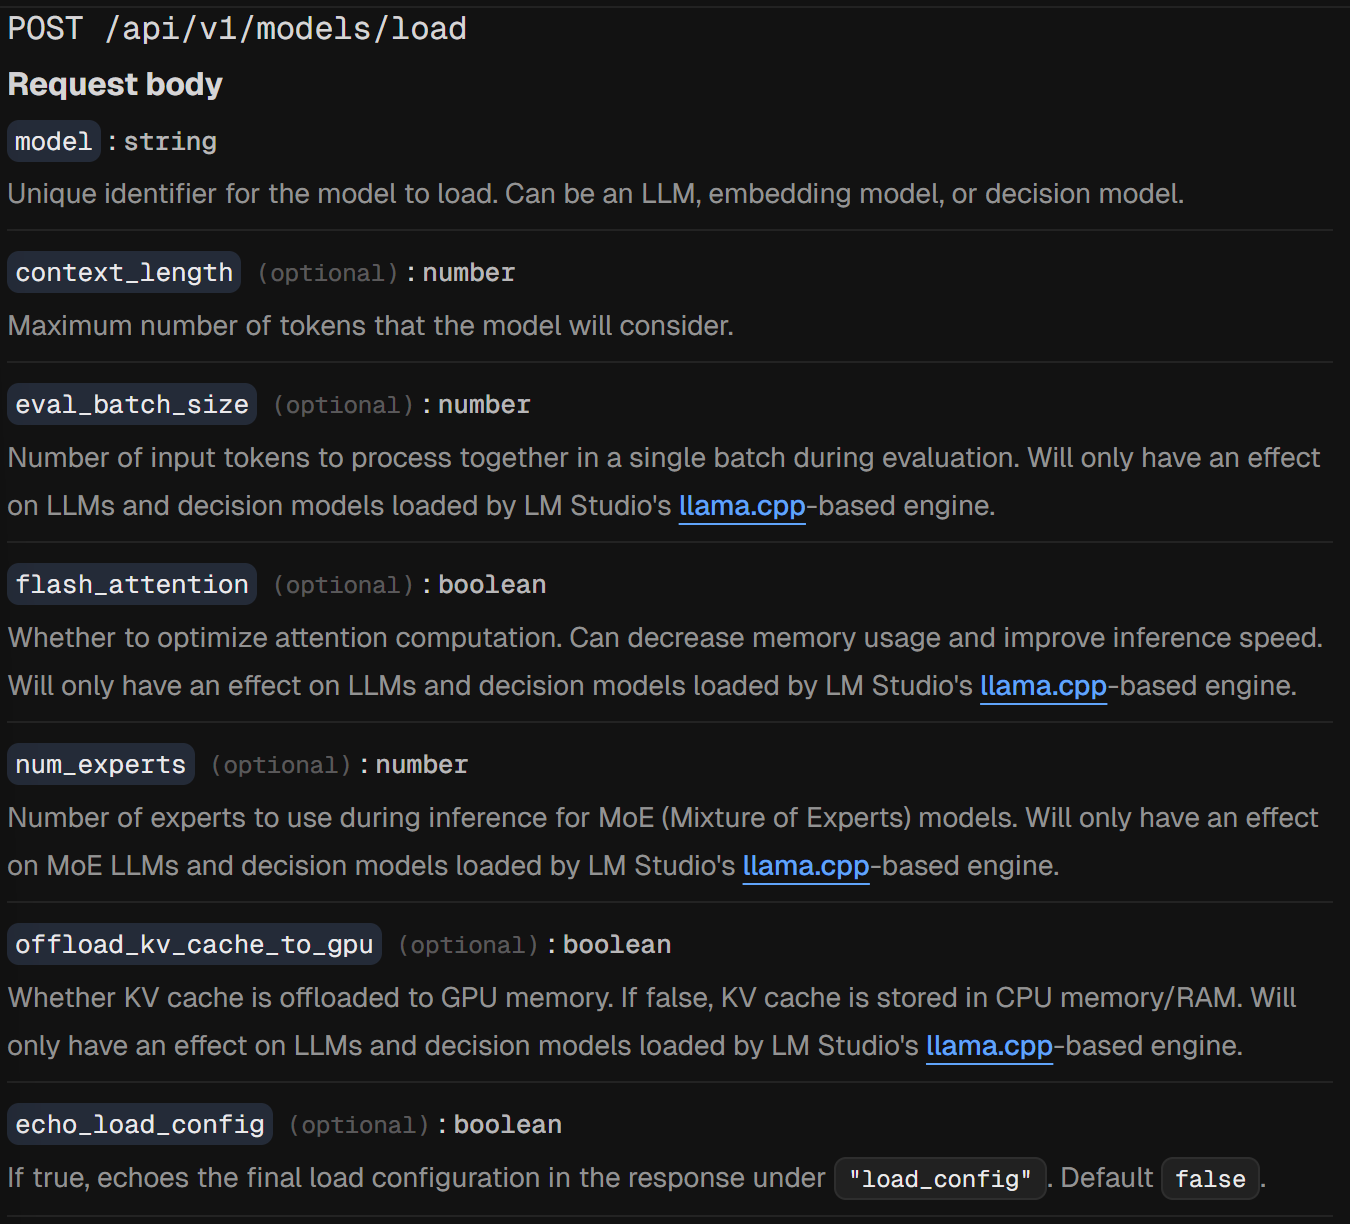

In [8]:
    # model: str,
    # context_length: int | None = None,
    # flash_attention: bool | None = None,
    # offload_kv_cache_to_gpu: bool | None = None,
    # eval_batch_size: int | None = None,
    # num_experts: int | None = None,



# Evaluation loop: one model + quant at a time
for key in ["qwen2.5-coder-0.5b-instruct"]:  # use keys from list_models()
    iid = load_model(key, context_length=8192, flash_attention=True, 
                     offload_kv_cache_to_gpu=True, eval_batch_size=8, num_experts=1)
    try:
        print(chat(iid, [{"role": "user", "content": "Test prompt"}], temperature=0.2))
    finally:
        unload_model(iid)  # frees VRAM before the next model

Loaded with: {'context_length': 8192, 'eval_batch_size': 8, 'physical_batch_size': 512, 'parallel': 4, 'flash_attention': True, 'lazy_mode': 'auto', 'context_checkpoints': 32, 'reasoning_budget_message': '', 'speculative_draft_mtp': False, 'speculative_draft_simple': False, 'speculative_draft_model': '', 'speculative_draft_max_tokens': 3, 'speculative_draft_min_tokens': 0, 'speculative_draft_min_continue_probability': 0, 'num_experts': 1, 'offload_kv_cache_to_gpu': True, 'prompt_template': {'type': 'jinja', 'template': '{%- if tools %}\n    {{- \'<|im_start|>system\\n\' }}\n    {%- if messages[0][\'role\'] == \'system\' %}\n        {{- messages[0][\'content\'] }}\n    {%- else %}\n        {{- \'You are Qwen, created by Alibaba Cloud. You are a helpful assistant.\' }}\n    {%- endif %}\n    {{- "\\n\\n# Tools\\n\\nYou may call one or more functions to assist with the user query.\\n\\nYou are provided with function signatures within <tools></tools> XML tags:\\n<tools>" }}\n    {%- for to

In [ ]:
# Interface for Hostprogram
# Ollama/LM Studio as implementation classes
# Methods required for tasks are in both implementations
# Attribute for persistence of model. This allows the host program to keep track of which model is currently loaded and manage resources accordingly.

# Skript for downloading all models in LM Studio, iterating through the available model keys and loading them with specified settings.

# Use ENV variables for model selection and model names, do not hardcode the selection
# Registry is needed, but only for the best 3 models. 
# Feedback model selection, the others are open.